In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import folium
import numpy as np
import seaborn as sb

In [18]:
data = pd.read_excel("ghgp_data_by_year_2023.xlsx", sheet_name='LDC - Direct Emissions', skiprows=3)
#data.head()
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 208 entries, 0 to 207
Data columns (total 26 columns):
 #   Column                                                                  Non-Null Count  Dtype  
---  ------                                                                  --------------  -----  
 0   Facility Id                                                             208 non-null    int64  
 1   FRS Id                                                                  193 non-null    float64
 2   Facility Name                                                           208 non-null    object 
 3   State where Emissions Occur                                             201 non-null    object 
 4   Reported City                                                           208 non-null    object 
 5   Reported State                                                          208 non-null    object 
 6   Reported Zip Code                                                       208 non-nu

In [23]:
data = data.fillna(data.mean(numeric_only=True))

In [24]:
#Convert entire dataframe to a numpy array
ghg_array = data.to_numpy()

#emission column are at indices 13 through 25
emissions_only = ghg_array[:, 13:].astype(float)

#Sum down columns ingnoring missing values
columns_sums = np.sum(emissions_only, axis=0)

In [29]:
print(columns_sums)

[15097669.60264968 15169067.20198758 15069159.34639521 15477887.22968675
 15793386.25532121 16388006.10770731 16269222.85155556 17054300.99031579
 17108074.81419209 16975388.07160221 17918099.25454546 17517858.32148634
 17808374.54933333]


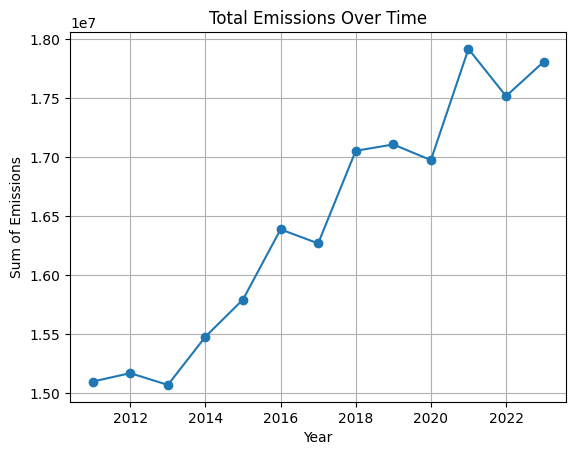

In [28]:
years = np.array([2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023])

plt.plot(years, columns_sums, marker='o')
plt.title("Total Emissions Over Time")
plt.xlabel("Year")
plt.ylabel("Sum of Emissions")
plt.grid(True)
plt.show()